Experimental Environment and Reproducibility


In [1]:
import os
import sys
import time
import random
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

output_dir = Path("/kaggle/working/imdb_revision")
output_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.20,
    "grid.linestyle": "--",
})

primary_color = "#1F4E79"
secondary_color = "#D97A2B"
neutral_color = "#7A7A7A"

device = "cuda" if torch.cuda.is_available() else "cpu"

environment_info = pd.DataFrame({
    "Item": [
        "Python",
        "Platform",
        "NumPy",
        "Pandas",
        "Scikit-learn",
        "PyTorch",
        "Device",
        "GPU"
    ],
    "Value": [
        sys.version.split()[0],
        platform.platform(),
        np.__version__,
        pd.__version__,
        sklearn.__version__,
        torch.__version__,
        device,
        torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available"
    ]
})

display(environment_info)
print("Output directory:", output_dir)

,Item,Value
0,Python,3.12.13
1,Platform,Linux-6.18.48+-x86_64-with-glibc2.35
2,NumPy,2.0.2
3,Pandas,2.3.3
4,Scikit-learn,1.6.1
5,PyTorch,2.10.0+cu128
6,Device,cuda
7,GPU,Tesla T4


Output directory: /kaggle/working/imdb_revision


Sentence-Transformer Environment

In [2]:
try:
    import sentence_transformers
except ImportError:
    !pip install -q sentence-transformers
    import sentence_transformers

from sentence_transformers import SentenceTransformer

print("Sentence Transformers:", sentence_transformers.__version__)

Sentence Transformers: 5.4.1


In [3]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("modules.json"):
    print("Model folder:", path.parent)

Model folder: /kaggle/input/models/srg9000/all-minilm-l6-v2/transformers/default/1/all-MiniLM-L6-v2


Cross-Validation Configuration

In [4]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5

cross_validator = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

print("Random seed:", SEED)
print(f"Cross-validation: Stratified {N_SPLITS}-fold")
print("Device:", device)

Random seed: 42
Cross-validation: Stratified 5-fold
Device: cuda


Dataset Loading and Integrity Analysis



In [5]:
input_dir = Path("/kaggle/input")

csv_files = list(input_dir.rglob("IMDB Dataset.csv"))

print("IMDb dataset files found:", len(csv_files))

for file in csv_files:
    print(file)

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one IMDB Dataset.csv file, found {len(csv_files)}"
    )

data_path = csv_files[0]
reviews = pd.read_csv(data_path)

exact_duplicates = reviews.duplicated().sum()
duplicate_reviews = reviews["review"].duplicated().sum()

review_label_counts = reviews.groupby("review")["sentiment"].nunique()
conflicting_reviews = review_label_counts[review_label_counts > 1]

integrity_summary = pd.DataFrame({
    "Measure": [
        "Total samples",
        "Positive reviews",
        "Negative reviews",
        "Missing reviews",
        "Missing labels",
        "Exact duplicate rows",
        "Duplicate review texts",
        "Conflicting-label reviews"
    ],
    "Value": [
        len(reviews),
        (reviews["sentiment"] == "positive").sum(),
        (reviews["sentiment"] == "negative").sum(),
        reviews["review"].isna().sum(),
        reviews["sentiment"].isna().sum(),
        exact_duplicates,
        duplicate_reviews,
        len(conflicting_reviews)
    ]
})

print("\nDataset path:", data_path)
print("Dataset shape:", reviews.shape)
print("Columns:", reviews.columns.tolist())

display(reviews.head())
display(integrity_summary)

IMDb dataset files found: 1
/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv

Dataset path: /kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv
Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


,Measure,Value
0,Total samples,50000
1,Positive reviews,25000
2,Negative reviews,25000
3,Missing reviews,0
4,Missing labels,0
5,Exact duplicate rows,418
6,Duplicate review texts,418
7,Conflicting-label reviews,0


Dataset Cleaning and Exploratory Data Analysis


In [6]:
reviews_clean = (
    reviews
    .drop_duplicates(subset=["review"], keep="first")
    .reset_index(drop=True)
)

reviews_clean["character_length"] = reviews_clean["review"].str.len()
reviews_clean["word_length"] = reviews_clean["review"].str.split().str.len()

class_counts = reviews_clean["sentiment"].value_counts()

length_summary = reviews_clean[
    ["character_length", "word_length"]
].describe().round(2)

print(f"Original samples: {len(reviews):,}")
print(f"Duplicates removed: {len(reviews) - len(reviews_clean):,}")
print(f"Final unique samples: {len(reviews_clean):,}")

print("\nClass distribution:")
display(class_counts.to_frame("Count"))

print("\nReview length statistics:")
display(length_summary)

Original samples: 50,000
Duplicates removed: 418
Final unique samples: 49,582

Class distribution:


,Count
sentiment,
positive,24884
negative,24698



Review length statistics:


,character_length,word_length
count,49582.00,49582.00
mean,1310.57,231.35
std,990.76,171.54
min,32.00,4.00
25%,699.00,126.00
50%,971.00,173.00
75%,1592.00,281.00
max,13704.00,2470.00


Class Distribution

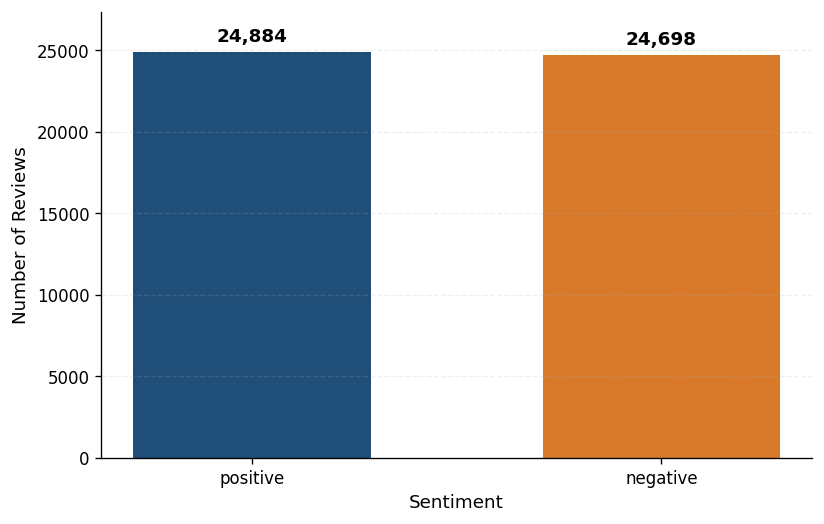

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=[primary_color, secondary_color],
    width=0.58
)

ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")
ax.grid(axis="x", visible=False)

for bar in bars:
    count = int(bar.get_height())
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + max(class_counts) * 0.015,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_ylim(0, max(class_counts) * 1.10)

plt.tight_layout()
plt.savefig(
    output_dir / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Review-Length Distribution

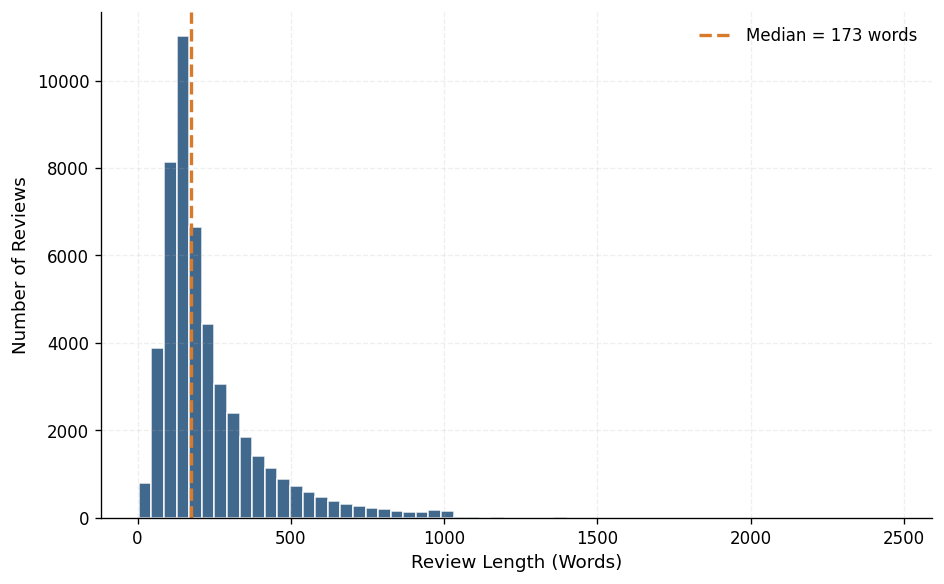

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    reviews_clean["word_length"],
    bins=60,
    color=primary_color,
    alpha=0.85,
    edgecolor="white"
)

median_words = reviews_clean["word_length"].median()

ax.axvline(
    median_words,
    color=secondary_color,
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_words:.0f} words"
)

ax.set_xlabel("Review Length (Words)")
ax.set_ylabel("Number of Reviews")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(
    output_dir / "review_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Cross-Validation Design and Sentence-BERT Input-Length Analysis

In [9]:
reviews_clean["label"] = reviews_clean["sentiment"].map({
    "negative": 0,
    "positive": 1
})

reviews_clean["fold"] = -1

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

for fold, (_, validation_idx) in enumerate(
    skf.split(reviews_clean["review"], reviews_clean["label"])
):
    reviews_clean.loc[validation_idx, "fold"] = fold

fold_summary = pd.crosstab(
    reviews_clean["fold"],
    reviews_clean["sentiment"],
    margins=True
)

display(fold_summary)

print("Samples assigned to folds:", (reviews_clean["fold"] >= 0).sum())
print("Unassigned samples:", (reviews_clean["fold"] < 0).sum())

sentiment,negative,positive,All
fold,,,
0,4940,4977,9917
1,4940,4977,9917
2,4939,4977,9916
3,4939,4977,9916
4,4940,4976,9916
All,24698,24884,49582


Samples assigned to folds: 49582
Unassigned samples: 0


### Sentence-BERT Model Configuration

This section defines the pretrained Sentence-BERT model used to generate sentence embeddings. A dedicated variable stores the model name so that it remains separate from classifier names used in the TF-IDF experiments. The configuration also reports the execution device, embedding dimension, and maximum sequence length.


In [10]:
from pathlib import Path
from sentence_transformers import SentenceTransformer

sbert_model_name = "sentence-transformers/all-MiniLM-L6-v2"

model_paths = list(Path("/kaggle/input").rglob("modules.json"))

if not model_paths:
    raise FileNotFoundError(
        "Sentence-BERT model not found. Check whether the Kaggle model dataset is attached."
    )

model_path = model_paths[0].parent

sbert_model = SentenceTransformer(
    str(model_path),
    device=device,
    local_files_only=True
)

tokenizer = sbert_model.tokenizer

print("Model:", sbert_model_name)
print("Model path:", model_path)
print("Device:", device)
print("Embedding dimension:", sbert_model.get_embedding_dimension())
print("Maximum sequence length:", sbert_model.max_seq_length)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: /kaggle/input/models/srg9000/all-minilm-l6-v2/transformers/default/1/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: sentence-transformers/all-MiniLM-L6-v2
Model path: /kaggle/input/models/srg9000/all-minilm-l6-v2/transformers/default/1/all-MiniLM-L6-v2
Device: cuda
Embedding dimension: 384
Maximum sequence length: 256


Token-Length and Truncation Analysis

In [11]:
from tqdm.auto import tqdm

batch_size = 512
token_lengths = []

review_texts = reviews_clean["review"].tolist()

for start in tqdm(range(0, len(review_texts), batch_size)):
    batch = review_texts[start:start + batch_size]

    encoded = tokenizer(
        batch,
        add_special_tokens=True,
        truncation=False,
        padding=False
    )

    token_lengths.extend(
        len(input_ids) for input_ids in encoded["input_ids"]
    )

reviews_clean["sbert_token_length"] = token_lengths

effective_limit = sbert_model.max_seq_length

reviews_clean["exceeds_sbert_limit"] = (
    reviews_clean["sbert_token_length"] > effective_limit
)

token_summary = reviews_clean["sbert_token_length"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2)

reviews_over_limit = reviews_clean["exceeds_sbert_limit"].sum()
percentage_over_limit = reviews_over_limit / len(reviews_clean) * 100

print("SBERT effective sequence limit:", effective_limit)
print(f"Reviews exceeding limit: {reviews_over_limit:,}")
print(f"Percentage exceeding limit: {percentage_over_limit:.2f}%")

display(token_summary.to_frame("Token Count"))

  0%|          | 0/97 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (417 > 256). Running this sequence through the model will result in indexing errors


SBERT effective sequence limit: 256
Reviews exceeding limit: 21,738
Percentage exceeding limit: 43.84%


,Token Count
count,49582.00
mean,310.57
std,231.37
min,10.00
25%,167.00
50%,231.00
75%,378.00
90%,610.00
95%,797.00
99%,1199.19


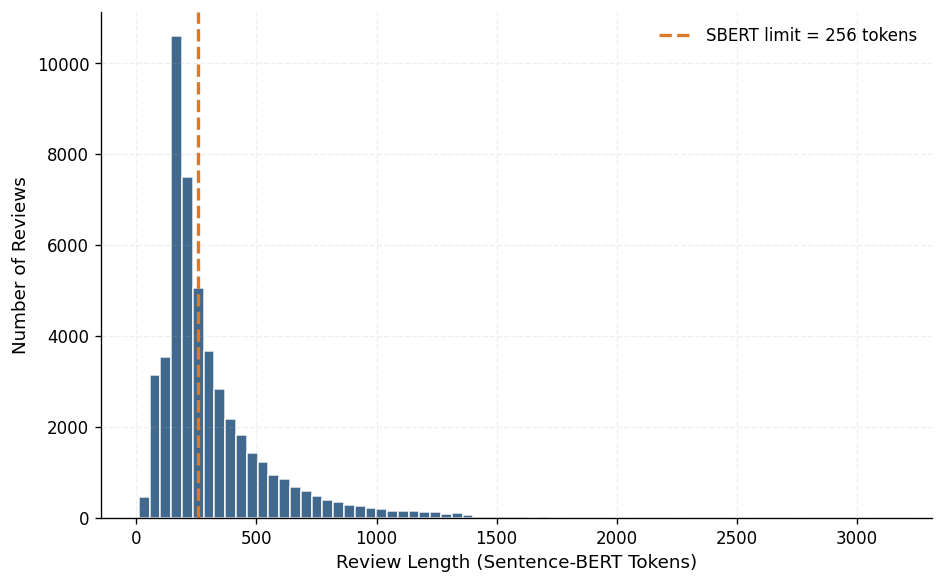

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    reviews_clean["sbert_token_length"],
    bins=70,
    color=primary_color,
    alpha=0.85,
    edgecolor="white"
)

ax.axvline(
    effective_limit,
    color=secondary_color,
    linestyle="--",
    linewidth=2,
    label=f"SBERT limit = {effective_limit} tokens"
)

ax.set_xlabel("Review Length (Sentence-BERT Tokens)")
ax.set_ylabel("Number of Reviews")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(
    output_dir / "sbert_token_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Representation-Specific Preprocessing and Ablation Design



In [13]:
import re
import html
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def minimal_clean(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def conventional_clean(text):
    text = minimal_clean(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]
    return " ".join(words)

In [14]:
start = time.perf_counter()
reviews_clean["text_minimal"] = reviews_clean["review"].apply(minimal_clean)
minimal_time = time.perf_counter() - start

start = time.perf_counter()
reviews_clean["text_conventional"] = reviews_clean["review"].apply(conventional_clean)
conventional_time = time.perf_counter() - start

preprocessing_summary = pd.DataFrame({
    "Condition": [
        "Raw text",
        "Minimal cleaning",
        "Conventional NLP"
    ],
    "Mean words": [
        reviews_clean["review"].str.split().str.len().mean(),
        reviews_clean["text_minimal"].str.split().str.len().mean(),
        reviews_clean["text_conventional"].str.split().str.len().mean()
    ],
    "Median words": [
        reviews_clean["review"].str.split().str.len().median(),
        reviews_clean["text_minimal"].str.split().str.len().median(),
        reviews_clean["text_conventional"].str.split().str.len().median()
    ],
    "Preprocessing time (s)": [
        0.0,
        minimal_time,
        conventional_time
    ]
}).round(2)

display(preprocessing_summary)

print("\nRAW:")
print(reviews_clean.loc[0, "review"][:500])

print("\nMINIMAL:")
print(reviews_clean.loc[0, "text_minimal"][:500])

print("\nCONVENTIONAL:")
print(reviews_clean.loc[0, "text_conventional"][:500])

,Condition,Mean words,Median words,Preprocessing time (s)
0,Raw text,231.35,173.0,0.00
1,Minimal cleaning,229.06,172.0,3.86
2,Conventional NLP,118.25,88.0,29.67



RAW:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

MINIMAL:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word. It is called OZ as t

Preprocessing Effect on Sentence-BERT Input Length

In [15]:
def get_token_lengths(texts, tokenizer, batch_size=512):
    lengths = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        encoded = tokenizer(
            batch,
            add_special_tokens=True,
            truncation=False,
            padding=False,
            verbose=False
        )

        lengths.extend(len(ids) for ids in encoded["input_ids"])

    return lengths


minimal_token_lengths = get_token_lengths(
    reviews_clean["text_minimal"].tolist(),
    tokenizer
)

conventional_token_lengths = get_token_lengths(
    reviews_clean["text_conventional"].tolist(),
    tokenizer
)

reviews_clean["sbert_tokens_minimal"] = minimal_token_lengths
reviews_clean["sbert_tokens_conventional"] = conventional_token_lengths

preprocessing_truncation = pd.DataFrame({
    "SBERT input": [
        "Minimal cleaning",
        "Conventional NLP"
    ],
    "Mean tokens": [
        np.mean(minimal_token_lengths),
        np.mean(conventional_token_lengths)
    ],
    "Median tokens": [
        np.median(minimal_token_lengths),
        np.median(conventional_token_lengths)
    ],
    "Reviews > 256": [
        np.sum(np.array(minimal_token_lengths) > effective_limit),
        np.sum(np.array(conventional_token_lengths) > effective_limit)
    ],
    "Reviews > 256 (%)": [
        np.mean(np.array(minimal_token_lengths) > effective_limit) * 100,
        np.mean(np.array(conventional_token_lengths) > effective_limit) * 100
    ]
}).round(2)

display(preprocessing_truncation)

,SBERT input,Mean tokens,Median tokens,Reviews > 256,Reviews > 256 (%)
0,Minimal cleaning,294.39,220.0,20167,40.67
1,Conventional NLP,135.66,100.0,5466,11.02


Sentence-BERT Feature Extraction and Long-Document Encoding

Direct Sentence-BERT — Minimal Preprocessing

In [16]:
minimal_texts = reviews_clean["text_minimal"].tolist()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

start = time.perf_counter()

sbert_direct_minimal = sbert_model.encode(
    minimal_texts,
    batch_size=128,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

direct_minimal_time = time.perf_counter() - start

print("Embedding shape:", sbert_direct_minimal.shape)
print(f"Encoding time: {direct_minimal_time:.2f} seconds")
print(
    f"Time per review: "
    f"{direct_minimal_time / len(minimal_texts) * 1000:.2f} ms"
)

Batches:   0%|          | 0/388 [00:00<?, ?it/s]

Embedding shape: (49582, 384)
Encoding time: 128.33 seconds
Time per review: 2.59 ms


Direct Sentence-BERT — Conventional Preprocessing

In [17]:
conventional_texts = reviews_clean["text_conventional"].tolist()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

start = time.perf_counter()

sbert_direct_conventional = sbert_model.encode(
    conventional_texts,
    batch_size=128,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

direct_conventional_time = time.perf_counter() - start

print("Embedding shape:", sbert_direct_conventional.shape)
print(f"Encoding time: {direct_conventional_time:.2f} seconds")
print(
    f"Time per review: "
    f"{direct_conventional_time / len(conventional_texts) * 1000:.2f} ms"
)

Batches:   0%|          | 0/388 [00:00<?, ?it/s]

Embedding shape: (49582, 384)
Encoding time: 77.93 seconds
Time per review: 1.57 ms


Chunked Sentence-BERT — Minimal Preprocessing

In [18]:
chunk_content_length = sbert_model.max_seq_length - 2

all_chunks = []
chunk_owner = []

for review_id, text in enumerate(minimal_texts):
    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False
    )

    chunks = [
        token_ids[i:i + chunk_content_length]
        for i in range(0, len(token_ids), chunk_content_length)
    ]

    if not chunks:
        chunks = [[]]

    for chunk in chunks:
        chunk_text = tokenizer.decode(
            chunk,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=True
        )

        all_chunks.append(chunk_text)
        chunk_owner.append(review_id)

chunk_counts = np.bincount(
    chunk_owner,
    minlength=len(minimal_texts)
)

print(f"Reviews: {len(minimal_texts):,}")
print(f"Total chunks: {len(all_chunks):,}")
print(f"Mean chunks per review: {chunk_counts.mean():.2f}")
print(f"Median chunks per review: {np.median(chunk_counts):.0f}")
print(f"Maximum chunks for one review: {chunk_counts.max()}")
print(f"Reviews requiring more than one chunk: {(chunk_counts > 1).sum():,}")
print(f"Percentage requiring chunking: {(chunk_counts > 1).mean() * 100:.2f}%")

Reviews: 49,582
Total chunks: 79,644
Mean chunks per review: 1.61
Median chunks per review: 1
Maximum chunks for one review: 12
Reviews requiring more than one chunk: 20,167
Percentage requiring chunking: 40.67%


In [19]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

start = time.perf_counter()

chunk_embeddings = sbert_model.encode(
    all_chunks,
    batch_size=128,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

chunk_encoding_time = time.perf_counter() - start

embedding_dim = chunk_embeddings.shape[1]

sbert_chunked_minimal = np.zeros(
    (len(minimal_texts), embedding_dim),
    dtype=np.float32
)

np.add.at(
    sbert_chunked_minimal,
    np.asarray(chunk_owner),
    chunk_embeddings
)

sbert_chunked_minimal /= chunk_counts[:, None]

print("Chunked embedding shape:", sbert_chunked_minimal.shape)
print(f"Chunk encoding time: {chunk_encoding_time:.2f} seconds")
print(
    f"Time per review: "
    f"{chunk_encoding_time / len(minimal_texts) * 1000:.2f} ms"
)

del chunk_embeddings

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Batches:   0%|          | 0/623 [00:00<?, ?it/s]

Chunked embedding shape: (49582, 384)
Chunk encoding time: 179.86 seconds
Time per review: 3.63 ms


Sentence-BERT Feature Extraction Summary and Checkpoint

In [20]:
encoding_summary = pd.DataFrame({
    "Strategy": [
        "Direct SBERT - Minimal",
        "Direct SBERT - Conventional",
        "Chunked SBERT - Minimal"
    ],
    "Feature dimension": [
        sbert_direct_minimal.shape[1],
        sbert_direct_conventional.shape[1],
        sbert_chunked_minimal.shape[1]
    ],
    "Units encoded": [
        len(minimal_texts),
        len(conventional_texts),
        len(all_chunks)
    ],
    "Feature extraction time (s)": [
        direct_minimal_time,
        direct_conventional_time,
        chunk_encoding_time
    ],
    "Time per review (ms)": [
        direct_minimal_time / len(minimal_texts) * 1000,
        direct_conventional_time / len(conventional_texts) * 1000,
        chunk_encoding_time / len(minimal_texts) * 1000
    ]
}).round(2)

display(encoding_summary)

np.save(
    output_dir / "sbert_direct_minimal.npy",
    sbert_direct_minimal
)

np.save(
    output_dir / "sbert_direct_conventional.npy",
    sbert_direct_conventional
)

np.save(
    output_dir / "sbert_chunked_minimal.npy",
    sbert_chunked_minimal
)

reviews_clean[
    ["sentiment", "label", "fold"]
].to_csv(
    output_dir / "experiment_index.csv",
    index=False
)

encoding_summary.to_csv(
    output_dir / "sbert_encoding_summary.csv",
    index=False
)

print("Saved to:", output_dir)

,Strategy,Feature dimension,Units encoded,Feature extraction time (s),Time per review (ms)
0,Direct SBERT - Minimal,384,49582,128.33,2.59
1,Direct SBERT - Conventional,384,49582,77.93,1.57
2,Chunked SBERT - Minimal,384,79644,179.86,3.63


Saved to: /kaggle/working/imdb_revision


Exploratory Pilot: TF-IDF and Classifier Hyperparameter Exploration


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import ParameterGrid

tfidf_grid = {
    "ngram_range": [(1, 1), (1, 2)],
    "max_features": [10000, 20000],
    "min_df": [2, 5],
    "max_df": [0.95, 1.0],
    "sublinear_tf": [True]
}

classifier_configs = {
    "LR": [
        LogisticRegression(C=0.5, max_iter=2000, solver="liblinear", random_state=42),
        LogisticRegression(C=1.0, max_iter=2000, solver="liblinear", random_state=42),
        LogisticRegression(C=2.0, max_iter=2000, solver="liblinear", random_state=42)
    ],
    "SVM": [
        LinearSVC(C=0.5, random_state=42),
        LinearSVC(C=1.0, random_state=42),
        LinearSVC(C=2.0, random_state=42)
    ],
    "MNB": [
        MultinomialNB(alpha=0.5),
        MultinomialNB(alpha=1.0),
        MultinomialNB(alpha=1.5)
    ]
}

print("TF-IDF configurations:", len(list(ParameterGrid(tfidf_grid))))
print(
    "Classifier configurations:",
    sum(len(v) for v in classifier_configs.values())
)

TF-IDF configurations: 16
Classifier configurations: 9


In [22]:
development_train = reviews_clean["fold"] != 0
development_valid = reviews_clean["fold"] == 0

text_conditions = {
    "TF-IDF Conventional": "text_conventional",
    "TF-IDF Minimal": "text_minimal"
}

search_results = []

for condition, text_column in text_conditions.items():
    train_text = reviews_clean.loc[development_train, text_column]
    valid_text = reviews_clean.loc[development_valid, text_column]

    y_train = reviews_clean.loc[development_train, "label"]
    y_valid = reviews_clean.loc[development_valid, "label"]

    for tfidf_params in ParameterGrid(tfidf_grid):
        vectorizer = TfidfVectorizer(**tfidf_params)

        start = time.perf_counter()
        X_train = vectorizer.fit_transform(train_text)
        X_valid = vectorizer.transform(valid_text)
        feature_time = time.perf_counter() - start

        for classifier_name, models in classifier_configs.items():
            for model in models:
                start = time.perf_counter()
                model.fit(X_train, y_train)
                training_time = time.perf_counter() - start

                start = time.perf_counter()
                predictions = model.predict(X_valid)
                inference_time = time.perf_counter() - start

                search_results.append({
                    "Condition": condition,
                    "Classifier": classifier_name,
                    "Model": str(model),
                    "Ngram": str(tfidf_params["ngram_range"]),
                    "Max features": tfidf_params["max_features"],
                    "Min df": tfidf_params["min_df"],
                    "Max df": tfidf_params["max_df"],
                    "Sublinear tf": tfidf_params["sublinear_tf"],
                    "Features generated": X_train.shape[1],
                    "Accuracy": accuracy_score(y_valid, predictions),
                    "Macro F1": f1_score(y_valid, predictions, average="macro"),
                    "Feature time (s)": feature_time,
                    "Training time (s)": training_time,
                    "Inference time (s)": inference_time
                })

search_results = pd.DataFrame(search_results)

print("Configurations evaluated:", len(search_results))

Configurations evaluated: 288


In [23]:
best_tfidf_configs = (
    search_results
    .sort_values(
        ["Macro F1", "Accuracy"],
        ascending=False
    )
    .groupby(
        ["Condition", "Classifier"],
        as_index=False
    )
    .first()
)

display(
    best_tfidf_configs[
        [
            "Condition",
            "Classifier",
            "Model",
            "Ngram",
            "Max features",
            "Min df",
            "Max df",
            "Sublinear tf",
            "Features generated",
            "Accuracy",
            "Macro F1"
        ]
    ].round(4)
)

search_results.to_csv(
    output_dir / "pilot_tfidf_search.csv",
    index=False
)

,Condition,Classifier,Model,Ngram,Max features,Min df,Max df,Sublinear tf,Features generated,Accuracy,Macro F1
0,TF-IDF Conventional,LR,"LogisticRegression(C=2.0, max_iter=2000, rando...","(1, 2)",20000,2,0.95,True,20000,0.9012,0.9012
1,TF-IDF Conventional,MNB,MultinomialNB(alpha=0.5),"(1, 2)",20000,5,0.95,True,20000,0.8717,0.8717
2,TF-IDF Conventional,SVM,"LinearSVC(C=0.5, random_state=42)","(1, 2)",20000,5,0.95,True,20000,0.8978,0.8977
3,TF-IDF Minimal,LR,"LogisticRegression(C=2.0, max_iter=2000, rando...","(1, 2)",20000,5,0.95,True,20000,0.9038,0.9038
4,TF-IDF Minimal,MNB,MultinomialNB(alpha=0.5),"(1, 2)",20000,2,0.95,True,20000,0.8726,0.8726
5,TF-IDF Minimal,SVM,"LinearSVC(C=0.5, random_state=42)","(1, 2)",20000,5,1.00,True,20000,0.9032,0.9032


Nested Five-Fold TF-IDF Evaluation

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tfidf_final_grid = {
    "ngram_range": [(1, 1), (1, 2)],
    "max_features": [10000, 20000],
    "min_df": [2],
    "max_df": [0.95],
    "sublinear_tf": [True]
}

tfidf_candidates = list(ParameterGrid(tfidf_final_grid))

model_candidates = {
    "LR": [
        ("C=0.5", lambda: LogisticRegression(
            C=0.5,
            max_iter=2000,
            solver="liblinear",
            random_state=SEED
        )),
        ("C=1.0", lambda: LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="liblinear",
            random_state=SEED
        ))
    ],
    "SVM": [
        ("C=0.5", lambda: LinearSVC(
            C=0.5,
            random_state=SEED
        )),
        ("C=1.0", lambda: LinearSVC(
            C=1.0,
            random_state=SEED
        ))
    ],
    "MNB": [
        ("alpha=0.5", lambda: MultinomialNB(
            alpha=0.5
        )),
        ("alpha=1.0", lambda: MultinomialNB(
            alpha=1.0
        ))
    ]
}

text_conditions = {
    "TF-IDF Minimal": "text_minimal",
    "TF-IDF Conventional": "text_conventional"
}

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

nested_results = []
tfidf_oof_predictions = {}

print("TF-IDF configurations:", len(tfidf_candidates))
print(
    "Classifier configurations:",
    sum(len(options) for options in model_candidates.values())
)
print("Text preprocessing conditions:", len(text_conditions))
print("Inner cross-validation folds:", inner_cv.n_splits)
print(
    "Total inner model evaluations:",
    len(tfidf_candidates)
    * sum(len(options) for options in model_candidates.values())
    * len(text_conditions)
    * 5
    * inner_cv.n_splits
)

TF-IDF configurations: 4
Classifier configurations: 6
Text preprocessing conditions: 2
Inner cross-validation folds: 3
Total inner model evaluations: 720


In [25]:
for condition, text_column in text_conditions.items():

    for classifier_name, classifier_options in model_candidates.items():

        print(f"\n{condition} + {classifier_name}")

        prediction_key = f"{condition} + {classifier_name}"
        tfidf_oof_predictions[prediction_key] = np.full(
            len(reviews_clean),
            -1,
            dtype=int
        )

        for outer_fold in range(5):

            outer_train_mask = reviews_clean["fold"] != outer_fold
            outer_valid_mask = reviews_clean["fold"] == outer_fold

            train_texts = reviews_clean.loc[
                outer_train_mask, text_column
            ].reset_index(drop=True)

            train_labels = reviews_clean.loc[
                outer_train_mask, "label"
            ].reset_index(drop=True)

            valid_texts = reviews_clean.loc[
                outer_valid_mask, text_column
            ]

            valid_labels = reviews_clean.loc[
                outer_valid_mask, "label"
            ]

            tuning_scores = []

            for tfidf_params in tfidf_candidates:
                for model_label, model_factory in classifier_options:

                    inner_scores = []

                    for inner_train_idx, inner_valid_idx in inner_cv.split(
                        train_texts,
                        train_labels
                    ):
                        vectorizer = TfidfVectorizer(**tfidf_params)

                        X_inner_train = vectorizer.fit_transform(
                            train_texts.iloc[inner_train_idx]
                        )

                        X_inner_valid = vectorizer.transform(
                            train_texts.iloc[inner_valid_idx]
                        )

                        model = model_factory()
                        model.fit(
                            X_inner_train,
                            train_labels.iloc[inner_train_idx]
                        )

                        predictions = model.predict(X_inner_valid)

                        inner_scores.append(
                            f1_score(
                                train_labels.iloc[inner_valid_idx],
                                predictions,
                                average="macro"
                            )
                        )

                    tuning_scores.append({
                        "tfidf": tfidf_params,
                        "model_label": model_label,
                        "model_factory": model_factory,
                        "mean_inner_f1": np.mean(inner_scores)
                    })

            best_config = max(
                tuning_scores,
                key=lambda x: x["mean_inner_f1"]
            )

            vectorizer = TfidfVectorizer(**best_config["tfidf"])

            start = time.perf_counter()
            X_outer_train = vectorizer.fit_transform(train_texts)
            X_outer_valid = vectorizer.transform(valid_texts)
            feature_time = time.perf_counter() - start

            model = best_config["model_factory"]()

            start = time.perf_counter()
            model.fit(X_outer_train, train_labels)
            training_time = time.perf_counter() - start

            start = time.perf_counter()
            predictions = model.predict(X_outer_valid)
            inference_time = time.perf_counter() - start

            valid_indices = reviews_clean.index[outer_valid_mask]
            tfidf_oof_predictions[prediction_key][valid_indices] = predictions

            nested_results.append({
                "Condition": condition,
                "Classifier": classifier_name,
                "Fold": outer_fold + 1,
                "Accuracy": accuracy_score(valid_labels, predictions),
                "Macro Precision": precision_score(
                    valid_labels,
                    predictions,
                    average="macro"
                ),
                "Macro Recall": recall_score(
                    valid_labels,
                    predictions,
                    average="macro"
                ),
                "Macro F1": f1_score(
                    valid_labels,
                    predictions,
                    average="macro"
                ),
                "Features": X_outer_train.shape[1],
                "Feature time (s)": feature_time,
                "Training time (s)": training_time,
                "Inference time (s)": inference_time,
                "Best TF-IDF": str(best_config["tfidf"]),
                "Best model": best_config["model_label"],
                "Inner Macro F1": best_config["mean_inner_f1"]
            })

            print(
                f"Fold {outer_fold + 1}: "
                f"F1={nested_results[-1]['Macro F1']:.4f} | "
                f"{best_config['model_label']}"
            )

nested_results = pd.DataFrame(nested_results)


TF-IDF Minimal + LR
Fold 1: F1=0.9018 | C=1.0
Fold 2: F1=0.9081 | C=1.0
Fold 3: F1=0.9093 | C=1.0
Fold 4: F1=0.9041 | C=1.0
Fold 5: F1=0.9034 | C=1.0

TF-IDF Minimal + SVM
Fold 1: F1=0.9028 | C=0.5
Fold 2: F1=0.9096 | C=0.5
Fold 3: F1=0.9103 | C=0.5
Fold 4: F1=0.9067 | C=0.5
Fold 5: F1=0.9049 | C=0.5

TF-IDF Minimal + MNB
Fold 1: F1=0.8726 | alpha=0.5
Fold 2: F1=0.8790 | alpha=0.5
Fold 3: F1=0.8794 | alpha=0.5
Fold 4: F1=0.8748 | alpha=0.5
Fold 5: F1=0.8754 | alpha=0.5

TF-IDF Conventional + LR
Fold 1: F1=0.8964 | C=1.0
Fold 2: F1=0.9012 | C=1.0
Fold 3: F1=0.9010 | C=1.0
Fold 4: F1=0.8985 | C=1.0
Fold 5: F1=0.8973 | C=1.0

TF-IDF Conventional + SVM
Fold 1: F1=0.8969 | C=0.5
Fold 2: F1=0.9011 | C=0.5
Fold 3: F1=0.8986 | C=0.5
Fold 4: F1=0.8987 | C=0.5
Fold 5: F1=0.8979 | C=0.5

TF-IDF Conventional + MNB
Fold 1: F1=0.8703 | alpha=1.0
Fold 2: F1=0.8783 | alpha=1.0
Fold 3: F1=0.8789 | alpha=1.0
Fold 4: F1=0.8713 | alpha=1.0
Fold 5: F1=0.8732 | alpha=1.0


TF-IDF Cross-Validation Summary

In [26]:
tfidf_cv_summary = (
    nested_results
    .groupby(["Condition", "Classifier"])
    .agg({
        "Accuracy": ["mean", "std"],
        "Macro Precision": ["mean", "std"],
        "Macro Recall": ["mean", "std"],
        "Macro F1": ["mean", "std"],
        "Feature time (s)": "mean",
        "Training time (s)": "mean",
        "Inference time (s)": "mean"
    })
)

tfidf_cv_summary.columns = [
    "Accuracy Mean",
    "Accuracy SD",
    "Precision Mean",
    "Precision SD",
    "Recall Mean",
    "Recall SD",
    "Macro F1 Mean",
    "Macro F1 SD",
    "Feature Time Mean (s)",
    "Training Time Mean (s)",
    "Inference Time Mean (s)"
]

tfidf_cv_summary = (
    tfidf_cv_summary
    .reset_index()
    .sort_values("Macro F1 Mean", ascending=False)
)

display(tfidf_cv_summary.round(4))

nested_results.to_csv(
    output_dir / "tfidf_fold_results.csv",
    index=False
)

tfidf_cv_summary.to_csv(
    output_dir / "tfidf_cv_summary.csv",
    index=False
)

,Condition,Classifier,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,Macro F1 Mean,Macro F1 SD,Feature Time Mean (s),Training Time Mean (s),Inference Time Mean (s)
5,TF-IDF Minimal,SVM,0.9069,0.0032,0.9069,0.0031,0.9069,0.0032,0.9069,0.0032,25.0157,2.0334,0.0056
3,TF-IDF Minimal,LR,0.9053,0.0032,0.9055,0.0032,0.9053,0.0032,0.9053,0.0032,25.2272,1.9125,0.0059
0,TF-IDF Conventional,LR,0.8989,0.0022,0.8992,0.0021,0.8989,0.0022,0.8989,0.0022,18.6235,0.8615,0.0032
2,TF-IDF Conventional,SVM,0.8987,0.0015,0.8988,0.0015,0.8986,0.0015,0.8987,0.0015,19.2841,0.9794,0.0032
4,TF-IDF Minimal,MNB,0.8763,0.0029,0.8764,0.0029,0.8762,0.0029,0.8762,0.0029,24.9395,0.0476,0.0088
1,TF-IDF Conventional,MNB,0.8744,0.0040,0.8747,0.0040,0.8744,0.0040,0.8744,0.0040,18.5473,0.0264,0.0049


Nested Five-Fold Sentence-BERT Classifier Evaluation

In [27]:
sbert_conditions = {
    "SBERT Direct Minimal": sbert_direct_minimal,
    "SBERT Direct Conventional": sbert_direct_conventional,
    "SBERT Chunked Minimal": sbert_chunked_minimal
}

sbert_model_candidates = {
    "LR": [
        ("C=0.5", lambda: LogisticRegression(
            C=0.5,
            max_iter=2000,
            solver="liblinear",
            random_state=SEED
        )),
        ("C=1.0", lambda: LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="liblinear",
            random_state=SEED
        )),
        ("C=2.0", lambda: LogisticRegression(
            C=2.0,
            max_iter=2000,
            solver="liblinear",
            random_state=SEED
        ))
    ],
    "SVM": [
        ("C=0.5", lambda: LinearSVC(C=0.5, random_state=SEED)),
        ("C=1.0", lambda: LinearSVC(C=1.0, random_state=SEED)),
        ("C=2.0", lambda: LinearSVC(C=2.0, random_state=SEED))
    ]
}

labels = reviews_clean["label"].to_numpy()

sbert_results = []
sbert_oof_predictions = {}

In [28]:
for condition, features in sbert_conditions.items():

    for classifier_name, classifier_options in sbert_model_candidates.items():

        print(f"\n{condition} + {classifier_name}")

        prediction_key = f"{condition} + {classifier_name}"
        sbert_oof_predictions[prediction_key] = np.full(
            len(reviews_clean),
            -1,
            dtype=int
        )

        for outer_fold in range(5):

            train_idx = np.where(
                reviews_clean["fold"].to_numpy() != outer_fold
            )[0]

            valid_idx = np.where(
                reviews_clean["fold"].to_numpy() == outer_fold
            )[0]

            X_train = features[train_idx]
            y_train = labels[train_idx]

            X_valid = features[valid_idx]
            y_valid = labels[valid_idx]

            tuning_scores = []

            inner_splitter = StratifiedKFold(
                n_splits=3,
                shuffle=True,
                random_state=SEED
            )

            for model_label, model_factory in classifier_options:

                inner_scores = []

                for inner_train_idx, inner_valid_idx in inner_splitter.split(
                    X_train,
                    y_train
                ):
                    model = model_factory()

                    model.fit(
                        X_train[inner_train_idx],
                        y_train[inner_train_idx]
                    )

                    inner_predictions = model.predict(
                        X_train[inner_valid_idx]
                    )

                    inner_scores.append(
                        f1_score(
                            y_train[inner_valid_idx],
                            inner_predictions,
                            average="macro"
                        )
                    )

                tuning_scores.append({
                    "model_label": model_label,
                    "model_factory": model_factory,
                    "mean_inner_f1": np.mean(inner_scores)
                })

            best_config = max(
                tuning_scores,
                key=lambda x: x["mean_inner_f1"]
            )

            model = best_config["model_factory"]()

            start = time.perf_counter()
            model.fit(X_train, y_train)
            training_time = time.perf_counter() - start

            start = time.perf_counter()
            predictions = model.predict(X_valid)
            inference_time = time.perf_counter() - start

            sbert_oof_predictions[prediction_key][valid_idx] = predictions

            sbert_results.append({
                "Condition": condition,
                "Classifier": classifier_name,
                "Fold": outer_fold + 1,
                "Accuracy": accuracy_score(y_valid, predictions),
                "Macro Precision": precision_score(
                    y_valid,
                    predictions,
                    average="macro"
                ),
                "Macro Recall": recall_score(
                    y_valid,
                    predictions,
                    average="macro"
                ),
                "Macro F1": f1_score(
                    y_valid,
                    predictions,
                    average="macro"
                ),
                "Features": features.shape[1],
                "Training time (s)": training_time,
                "Inference time (s)": inference_time,
                "Best model": best_config["model_label"],
                "Inner Macro F1": best_config["mean_inner_f1"]
            })

            print(
                f"Fold {outer_fold + 1}: "
                f"F1={sbert_results[-1]['Macro F1']:.4f} | "
                f"{best_config['model_label']}"
            )

sbert_results = pd.DataFrame(sbert_results)


SBERT Direct Minimal + LR
Fold 1: F1=0.8143 | C=2.0
Fold 2: F1=0.8231 | C=2.0
Fold 3: F1=0.8248 | C=2.0
Fold 4: F1=0.8179 | C=2.0
Fold 5: F1=0.8176 | C=2.0

SBERT Direct Minimal + SVM
Fold 1: F1=0.8158 | C=0.5
Fold 2: F1=0.8233 | C=0.5
Fold 3: F1=0.8279 | C=2.0
Fold 4: F1=0.8185 | C=0.5
Fold 5: F1=0.8178 | C=1.0

SBERT Direct Conventional + LR
Fold 1: F1=0.8234 | C=2.0
Fold 2: F1=0.8338 | C=2.0
Fold 3: F1=0.8300 | C=2.0
Fold 4: F1=0.8227 | C=2.0
Fold 5: F1=0.8262 | C=2.0

SBERT Direct Conventional + SVM
Fold 1: F1=0.8226 | C=2.0
Fold 2: F1=0.8350 | C=1.0
Fold 3: F1=0.8334 | C=0.5
Fold 4: F1=0.8263 | C=2.0
Fold 5: F1=0.8288 | C=2.0

SBERT Chunked Minimal + LR
Fold 1: F1=0.8301 | C=2.0
Fold 2: F1=0.8402 | C=2.0
Fold 3: F1=0.8411 | C=2.0
Fold 4: F1=0.8355 | C=2.0
Fold 5: F1=0.8287 | C=2.0

SBERT Chunked Minimal + SVM
Fold 1: F1=0.8318 | C=2.0
Fold 2: F1=0.8437 | C=2.0
Fold 3: F1=0.8420 | C=1.0
Fold 4: F1=0.8357 | C=1.0
Fold 5: F1=0.8334 | C=2.0


Sentence-BERT Cross-Validation Summary

In [29]:
sbert_cv_summary = (
    sbert_results
    .groupby(["Condition", "Classifier"])
    .agg({
        "Accuracy": ["mean", "std"],
        "Macro Precision": ["mean", "std"],
        "Macro Recall": ["mean", "std"],
        "Macro F1": ["mean", "std"],
        "Training time (s)": "mean",
        "Inference time (s)": "mean"
    })
)

sbert_cv_summary.columns = [
    "Accuracy Mean",
    "Accuracy SD",
    "Precision Mean",
    "Precision SD",
    "Recall Mean",
    "Recall SD",
    "Macro F1 Mean",
    "Macro F1 SD",
    "Training Time Mean (s)",
    "Inference Time Mean (s)"
]

sbert_cv_summary = (
    sbert_cv_summary
    .reset_index()
    .sort_values("Macro F1 Mean", ascending=False)
)

display(sbert_cv_summary.round(4))

sbert_results.to_csv(
    output_dir / "sbert_fold_results.csv",
    index=False
)

sbert_cv_summary.to_csv(
    output_dir / "sbert_cv_summary.csv",
    index=False
)

,Condition,Classifier,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,Macro F1 Mean,Macro F1 SD,Training Time Mean (s),Inference Time Mean (s)
1,SBERT Chunked Minimal,SVM,0.8373,0.0053,0.8373,0.0053,0.8373,0.0053,0.8373,0.0053,6.5448,0.0079
0,SBERT Chunked Minimal,LR,0.8351,0.0057,0.8351,0.0057,0.8351,0.0057,0.8351,0.0057,5.8933,0.0078
3,SBERT Direct Conventional,SVM,0.8292,0.0051,0.8293,0.0051,0.8292,0.0051,0.8292,0.0051,6.6858,0.0077
2,SBERT Direct Conventional,LR,0.8272,0.0047,0.8273,0.0047,0.8272,0.0047,0.8272,0.0047,6.0164,0.0079
5,SBERT Direct Minimal,SVM,0.8207,0.0049,0.8208,0.0049,0.8207,0.0049,0.8207,0.0049,5.4493,0.0076
4,SBERT Direct Minimal,LR,0.8195,0.0043,0.8196,0.0043,0.8195,0.0043,0.8195,0.0043,6.1074,0.0089


Accuracy–Efficiency Comparison

In [30]:
tfidf_comparison = tfidf_cv_summary.copy()

tfidf_comparison["Method"] = (
    tfidf_comparison["Condition"]
    + " + "
    + tfidf_comparison["Classifier"]
)

tfidf_comparison["Feature Dimension"] = 20000

sbert_comparison = sbert_cv_summary.copy()

sbert_comparison["Method"] = (
    sbert_comparison["Condition"]
    + " + "
    + sbert_comparison["Classifier"]
)

sbert_comparison["Feature Dimension"] = 384

performance_comparison = pd.concat([
    tfidf_comparison[
        [
            "Method",
            "Accuracy Mean",
            "Accuracy SD",
            "Macro F1 Mean",
            "Macro F1 SD",
            "Training Time Mean (s)",
            "Inference Time Mean (s)",
            "Feature Dimension"
        ]
    ],
    sbert_comparison[
        [
            "Method",
            "Accuracy Mean",
            "Accuracy SD",
            "Macro F1 Mean",
            "Macro F1 SD",
            "Training Time Mean (s)",
            "Inference Time Mean (s)",
            "Feature Dimension"
        ]
    ]
], ignore_index=True)

performance_comparison = performance_comparison.sort_values(
    "Macro F1 Mean",
    ascending=False
)

display(performance_comparison.round(4))

performance_comparison.to_csv(
    output_dir / "performance_comparison.csv",
    index=False
)

,Method,Accuracy Mean,Accuracy SD,Macro F1 Mean,Macro F1 SD,Training Time Mean (s),Inference Time Mean (s),Feature Dimension
0,TF-IDF Minimal + SVM,0.9069,0.0032,0.9069,0.0032,2.0334,0.0056,20000
1,TF-IDF Minimal + LR,0.9053,0.0032,0.9053,0.0032,1.9125,0.0059,20000
2,TF-IDF Conventional + LR,0.8989,0.0022,0.8989,0.0022,0.8615,0.0032,20000
3,TF-IDF Conventional + SVM,0.8987,0.0015,0.8987,0.0015,0.9794,0.0032,20000
4,TF-IDF Minimal + MNB,0.8763,0.0029,0.8762,0.0029,0.0476,0.0088,20000
5,TF-IDF Conventional + MNB,0.8744,0.0040,0.8744,0.0040,0.0264,0.0049,20000
6,SBERT Chunked Minimal + SVM,0.8373,0.0053,0.8373,0.0053,6.5448,0.0079,384
7,SBERT Chunked Minimal + LR,0.8351,0.0057,0.8351,0.0057,5.8933,0.0078,384
8,SBERT Direct Conventional + SVM,0.8292,0.0051,0.8292,0.0051,6.6858,0.0077,384
9,SBERT Direct Conventional + LR,0.8272,0.0047,0.8272,0.0047,6.0164,0.0079,384


Statistical Significance Analysis

In [31]:
from scipy.stats import wilcoxon

all_fold_results = pd.concat([
    nested_results[
        ["Condition", "Classifier", "Fold", "Macro F1"]
    ],
    sbert_results[
        ["Condition", "Classifier", "Fold", "Macro F1"]
    ]
], ignore_index=True)

all_fold_results["Method"] = (
    all_fold_results["Condition"]
    + " + "
    + all_fold_results["Classifier"]
)

method_mean_f1 = (
    all_fold_results
    .groupby("Method")["Macro F1"]
    .mean()
    .sort_values(ascending=False)
)

display(method_mean_f1.to_frame("Mean Macro F1"))

,Mean Macro F1
Method,
TF-IDF Minimal + SVM,0.906874
TF-IDF Minimal + LR,0.905334
TF-IDF Conventional + LR,0.898888
TF-IDF Conventional + SVM,0.898659
TF-IDF Minimal + MNB,0.876247
TF-IDF Conventional + MNB,0.874395
SBERT Chunked Minimal + SVM,0.837311
SBERT Chunked Minimal + LR,0.835094
SBERT Direct Conventional + SVM,0.829214


In [32]:
methods = method_mean_f1.index.tolist()

wilcoxon_results = []

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):

        method_a = methods[i]
        method_b = methods[j]

        scores_a = (
            all_fold_results[
                all_fold_results["Method"] == method_a
            ]
            .sort_values("Fold")["Macro F1"]
            .to_numpy()
        )

        scores_b = (
            all_fold_results[
                all_fold_results["Method"] == method_b
            ]
            .sort_values("Fold")["Macro F1"]
            .to_numpy()
        )

        if np.allclose(scores_a, scores_b):
            statistic = 0.0
            p_value = 1.0
        else:
            statistic, p_value = wilcoxon(scores_a, scores_b)

        wilcoxon_results.append({
            "Method A": method_a,
            "Method B": method_b,
            "Wilcoxon statistic": statistic,
            "p-value": p_value
        })

wilcoxon_results = pd.DataFrame(wilcoxon_results)

display(
    wilcoxon_results
    .sort_values("p-value")
    .round(4)
)

wilcoxon_results.to_csv(
    output_dir / "wilcoxon_results.csv",
    index=False
)

,Method A,Method B,Wilcoxon statistic,p-value
0,TF-IDF Minimal + SVM,TF-IDF Minimal + LR,0.0,0.0625
1,TF-IDF Minimal + SVM,TF-IDF Conventional + LR,0.0,0.0625
2,TF-IDF Minimal + SVM,TF-IDF Conventional + SVM,0.0,0.0625
3,TF-IDF Minimal + SVM,TF-IDF Minimal + MNB,0.0,0.0625
4,TF-IDF Minimal + SVM,TF-IDF Conventional + MNB,0.0,0.0625
...,...,...,...,...
64,SBERT Direct Conventional + LR,SBERT Direct Minimal + LR,0.0,0.0625
65,SBERT Direct Minimal + SVM,SBERT Direct Minimal + LR,0.0,0.0625
56,SBERT Chunked Minimal + LR,SBERT Direct Conventional + SVM,1.0,0.1250
60,SBERT Direct Conventional + SVM,SBERT Direct Conventional + LR,1.0,0.1250


Out-of-Fold Error Analysi

In [33]:
best_tfidf_method = (
    tfidf_cv_summary
    .sort_values("Macro F1 Mean", ascending=False)
    .iloc[0]
)

best_sbert_method = (
    sbert_cv_summary
    .sort_values("Macro F1 Mean", ascending=False)
    .iloc[0]
)

best_tfidf_key = (
    f"{best_tfidf_method['Condition']} + "
    f"{best_tfidf_method['Classifier']}"
)

best_sbert_key = (
    f"{best_sbert_method['Condition']} + "
    f"{best_sbert_method['Classifier']}"
)

tfidf_predictions = tfidf_oof_predictions[best_tfidf_key]
sbert_predictions = sbert_oof_predictions[best_sbert_key]

true_labels = reviews_clean["label"].to_numpy()

error_analysis = reviews_clean[
    [
        "review",
        "sentiment",
        "word_length",
        "sbert_token_length",
        "fold"
    ]
].copy()

error_analysis["TF-IDF prediction"] = tfidf_predictions
error_analysis["SBERT prediction"] = sbert_predictions

error_analysis["Category"] = np.select(
    [
        (tfidf_predictions == true_labels) &
        (sbert_predictions == true_labels),

        (tfidf_predictions == true_labels) &
        (sbert_predictions != true_labels),

        (tfidf_predictions != true_labels) &
        (sbert_predictions == true_labels),

        (tfidf_predictions != true_labels) &
        (sbert_predictions != true_labels)
    ],
    [
        "Both correct",
        "TF-IDF correct / SBERT wrong",
        "SBERT correct / TF-IDF wrong",
        "Both wrong"
    ],
    default="Unclassified"
)

error_counts = error_analysis["Category"].value_counts()

display(error_counts.to_frame("Reviews"))

error_analysis.to_csv(
    output_dir / "error_analysis.csv",
    index=False
)

,Reviews
Category,
Both correct,39379
TF-IDF correct / SBERT wrong,5586
Both wrong,2480
SBERT correct / TF-IDF wrong,2137


In [34]:
for category in [
    "TF-IDF correct / SBERT wrong",
    "SBERT correct / TF-IDF wrong",
    "Both wrong"
]:
    print(f"\n{category}")
    
    examples = (
        error_analysis[
            error_analysis["Category"] == category
        ]
        .sort_values("sbert_token_length", ascending=False)
        .head(5)
    )

    display(
        examples[
            [
                "sentiment",
                "word_length",
                "sbert_token_length",
                "review"
            ]
        ]
    )


TF-IDF correct / SBERT wrong


,sentiment,word_length,sbert_token_length,review
31265,positive,2125,2900,"Back in the mid/late 80s, an OAV anime by titl..."
3024,positive,1737,2293,If anyone ever assembles a compendium on moder...
32407,negative,1263,1683,Raising Victor Vargas: A Review<br /><br />You...
556,positive,1296,1666,I thought that ROTJ was clearly the best out o...
17573,positive,1196,1529,The premise of this movie has been tickling my...



SBERT correct / TF-IDF wrong


,sentiment,word_length,sbert_token_length,review
11170,positive,996,1529,I felt duty bound to watch the 1983 Timothy Da...
37118,negative,998,1443,N.B.: Spoilers within. Assigning an artistic d...
24495,positive,1010,1416,Watching Cliffhanger makes me nostalgic for th...
25513,positive,986,1415,WAQT is a perfect example of a chicken soup no...
41939,positive,991,1396,Once again I must play something of the contra...



Both wrong


,sentiment,word_length,sbert_token_length,review
31072,positive,2108,3035,"(Some spoilers included:)<br /><br />Although,..."
16722,positive,996,1423,"The film had NO help at all, promotion-wise: i..."
4150,negative,993,1401,Hear are some of the interesting things our co...
20565,negative,951,1393,"Anyone who visited drive-ins in the 1950s, 60s..."
18445,negative,1014,1383,"Within the realm of Science Fiction, two parti..."


McNemar's Test for Paired Classification Comparison

In [35]:

from scipy.stats import binomtest

tfidf_correct = tfidf_predictions == true_labels
sbert_correct = sbert_predictions == true_labels

tfidf_only_correct = np.sum(
    tfidf_correct & ~sbert_correct
)

sbert_only_correct = np.sum(
    ~tfidf_correct & sbert_correct
)

discordant_total = tfidf_only_correct + sbert_only_correct

mcnemar_p = (
    binomtest(
        tfidf_only_correct,
        n=discordant_total,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if discordant_total > 0
    else 1.0
)

mcnemar_results = pd.DataFrame({
    "Measure": [
        "TF-IDF correct, SBERT wrong",
        "SBERT correct, TF-IDF wrong",
        "Total discordant predictions",
        "Exact McNemar p-value"
    ],
    "Value": [
        tfidf_only_correct,
        sbert_only_correct,
        discordant_total,
        mcnemar_p
    ]
})

display(mcnemar_results)

print(
    "Statistically significant difference (p < 0.05)."
    if mcnemar_p < 0.05
    else "No statistically significant difference (p >= 0.05)."
)

mcnemar_results.to_csv(
    output_dir / "mcnemar_results.csv",
    index=False
)


,Measure,Value
0,"TF-IDF correct, SBERT wrong",5586.0
1,"SBERT correct, TF-IDF wrong",2137.0
2,Total discordant predictions,7723.0
3,Exact McNemar p-value,0.0


Statistically significant difference (p < 0.05).


Final Comparative Results and Publication Outputs

In [36]:
final_results = performance_comparison.copy()

final_results["Accuracy"] = final_results.apply(
    lambda row:
    f"{row['Accuracy Mean']:.4f} ± {row['Accuracy SD']:.4f}",
    axis=1
)

final_results["Macro F1"] = final_results.apply(
    lambda row:
    f"{row['Macro F1 Mean']:.4f} ± {row['Macro F1 SD']:.4f}",
    axis=1
)

final_table = final_results[
    [
        "Method",
        "Accuracy",
        "Macro F1",
        "Feature Dimension",
        "Training Time Mean (s)",
        "Inference Time Mean (s)"
    ]
]

display(final_table)

final_table.to_csv(
    output_dir / "final_results_table.csv",
    index=False
)

,Method,Accuracy,Macro F1,Feature Dimension,Training Time Mean (s),Inference Time Mean (s)
0,TF-IDF Minimal + SVM,0.9069 ± 0.0032,0.9069 ± 0.0032,20000,2.033413,0.005605
1,TF-IDF Minimal + LR,0.9053 ± 0.0032,0.9053 ± 0.0032,20000,1.912458,0.005934
2,TF-IDF Conventional + LR,0.8989 ± 0.0022,0.8989 ± 0.0022,20000,0.861546,0.003159
3,TF-IDF Conventional + SVM,0.8987 ± 0.0015,0.8987 ± 0.0015,20000,0.979395,0.003200
4,TF-IDF Minimal + MNB,0.8763 ± 0.0029,0.8762 ± 0.0029,20000,0.047647,0.008825
5,TF-IDF Conventional + MNB,0.8744 ± 0.0040,0.8744 ± 0.0040,20000,0.026373,0.004906
6,SBERT Chunked Minimal + SVM,0.8373 ± 0.0053,0.8373 ± 0.0053,384,6.544840,0.007890
7,SBERT Chunked Minimal + LR,0.8351 ± 0.0057,0.8351 ± 0.0057,384,5.893333,0.007801
8,SBERT Direct Conventional + SVM,0.8292 ± 0.0051,0.8292 ± 0.0051,384,6.685849,0.007731
9,SBERT Direct Conventional + LR,0.8272 ± 0.0047,0.8272 ± 0.0047,384,6.016426,0.007856


Final Performance Figure

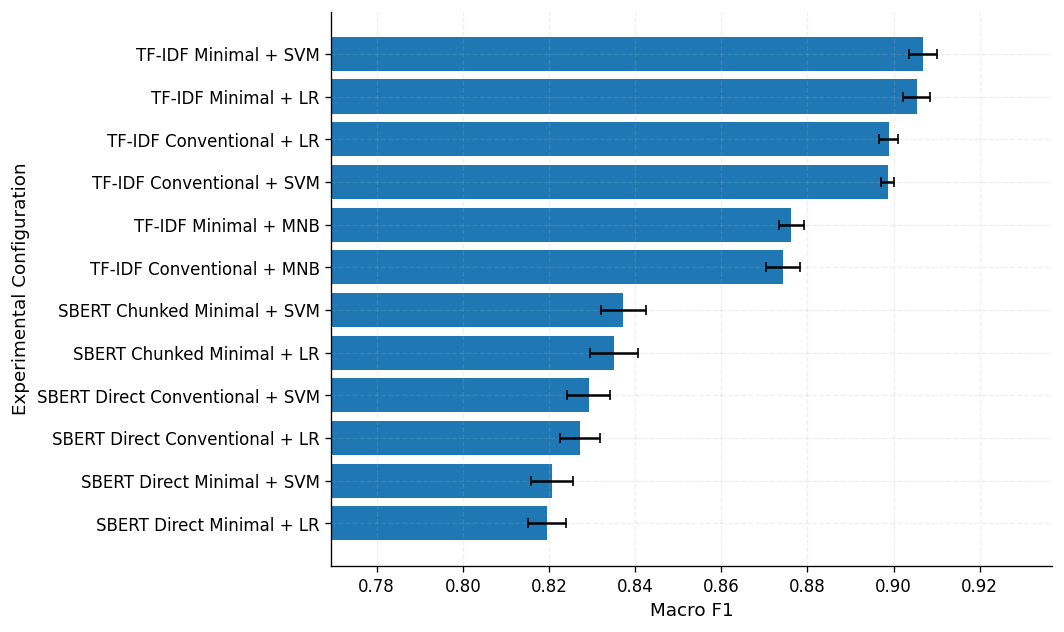

In [37]:
plot_data = performance_comparison.sort_values(
    "Macro F1 Mean",
    ascending=True
)

fig, ax = plt.subplots(
    figsize=(9, max(5, len(plot_data) * 0.45))
)

ax.barh(
    plot_data["Method"],
    plot_data["Macro F1 Mean"],
    xerr=plot_data["Macro F1 SD"],
    capsize=3
)

ax.set_xlabel("Macro F1")
ax.set_ylabel("Experimental Configuration")
ax.set_xlim(
    max(0, plot_data["Macro F1 Mean"].min() - 0.05),
    min(1.0, plot_data["Macro F1 Mean"].max() + 0.03)
)

plt.tight_layout()

plt.savefig(
    output_dir / "final_macro_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Export Experiment Configuration

This section records the main experimental settings used in the study, including the dataset, sample counts, cross-validation settings, Sentence-BERT model configuration, and TF-IDF parameters. The configuration is exported to a CSV file to support clear reporting and reproducibility.


In [38]:
experiment_configuration = pd.DataFrame({
    "Setting": [
        "Dataset",
        "Original samples",
        "Unique samples after deduplication",
        "Random seed",
        "Outer folds",
        "Inner folds",
        "Sentence-BERT model",
        "SBERT maximum sequence length",
        "SBERT embedding dimension",
        "Chunk content length",
        "TF-IDF maximum features",
        "Primary selection metric"
    ],
    "Value": [
        "IMDb Movie Reviews",
        len(reviews),
        len(reviews_clean),
        SEED,
        5,
        3,
        sbert_model_name,
        effective_limit,
        sbert_model.get_embedding_dimension(),
        chunk_content_length,
        20000,
        "Macro F1"
    ]
})

display(experiment_configuration)

experiment_configuration.to_csv(
    output_dir / "experiment_configuration.csv",
    index=False
)

print("\nFinal output directory:")
print(output_dir)

print("\nGenerated files:")
for file in sorted(output_dir.iterdir()):
    print(file.name)

,Setting,Value
0,Dataset,IMDb Movie Reviews
1,Original samples,50000
2,Unique samples after deduplication,49582
3,Random seed,42
4,Outer folds,5
5,Inner folds,3
6,Sentence-BERT model,sentence-transformers/all-MiniLM-L6-v2
7,SBERT maximum sequence length,256
8,SBERT embedding dimension,384
9,Chunk content length,254



Final output directory:
/kaggle/working/imdb_revision

Generated files:
class_distribution.png
error_analysis.csv
experiment_configuration.csv
experiment_index.csv
final_macro_f1_comparison.png
final_results_table.csv
mcnemar_results.csv
performance_comparison.csv
pilot_tfidf_search.csv
review_length_distribution.png
sbert_chunked_minimal.npy
sbert_cv_summary.csv
sbert_direct_conventional.npy
sbert_direct_minimal.npy
sbert_encoding_summary.csv
sbert_fold_results.csv
sbert_token_length_distribution.png
tfidf_cv_summary.csv
tfidf_fold_results.csv
wilcoxon_results.csv
